# 04 – Modèle ML (LightGBM) vs momentum vs marché

Le momentum 12-1 est une **règle fixe**. Ici on laisse un modèle de gradient boosting (LightGBM) apprendre à classer les actions à partir de plusieurs signaux — momentum à 3/6/12 mois, retournement court terme, volatilité récente. Question de l'étape 5 :

> **Un modèle qui apprend fait-il mieux qu'une règle simple ?**

Protocole **walk-forward**, sans look-ahead : à chaque fin de mois, on ré-entraîne le modèle sur tout le passé, on prédit le rendement du mois suivant, et on détient le top 20 %. Le modèle n'est donc **jamais** testé sur des données qu'il a vues à l'entraînement.

Prérequis : `python src/ingest.py` et le module `src/ml.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from analytics import drawdown, load_prices
from backtest import backtest_momentum, equity_curve, performance
from ml import build_panel, walk_forward_predict, ml_backtest, feature_importance

plt.rcParams['figure.figsize'] = (11, 5)
pd.options.display.float_format = '{:.3f}'.format

# bleu = ML (la nouveauté), orange = momentum (la règle), gris = marché
ML, MOM, BENCH = '#2563eb', '#f59e0b', '#9ca3af'

prices = load_prices(ROOT / 'data' / 'market.duckdb')
panel = build_panel(prices)
preds = walk_forward_predict(panel, min_train_months=36)

ml_bt = ml_backtest(prices, preds, frac=0.2, cost_bps=10)
mom_bt = backtest_momentum(prices, frac=0.2, cost_bps=10)

# le ML démarre plus tard (36 mois de warm-up) -> on compare sur la période commune
start = max(ml_bt.index[0], mom_bt.index[0])
comp = pd.DataFrame({
    'ML': ml_bt['strategy'],
    'Momentum': mom_bt['strategy'],
    'Marché': ml_bt['benchmark'],
}).loc[start:].dropna()
print(f'{len(comp)} mois, du {comp.index[0]:%m/%Y} au {comp.index[-1]:%m/%Y}')

93 mois, du 02/2019 au 10/2026


## 1. Ce que le modèle voit

À chaque fin de mois, chaque action est décrite par 5 features connues à cette date ; la **cible** est le rendement du mois *suivant* (jamais donnée en entrée). Un aperçu du panel (date × ticker) :

In [2]:
panel.head()

mom_3  mom_6  mom_12  rev_1  vol_6  target
date       ticker                                            
2016-01-31 AAPL   -0.115 -0.125  -0.086 -0.075  0.068  -0.001
           ABBV   -0.005 -0.146   0.006 -0.064  0.086  -0.005
           ABT     0.002 -0.109   0.019 -0.152  0.101   0.024
           ADBE    0.060  0.146   0.340 -0.051  0.051  -0.045
           AMGN    0.031 -0.072   0.088 -0.059  0.099  -0.062

Rien de magique côté données : ce sont les mêmes ingrédients que le momentum, enrichis d'un signal de retournement (`rev_1`) et de volatilité (`vol_6`). Toute la valeur ajoutée espérée vient de la **façon dont le modèle les combine**.

## 2. Sur quoi le modèle s'appuie-t-il ?

Importance des features (gain), modèle entraîné sur l'ensemble du panel — purement descriptif. On veut savoir si le modèle mise tout sur un signal ou s'il les mélange.

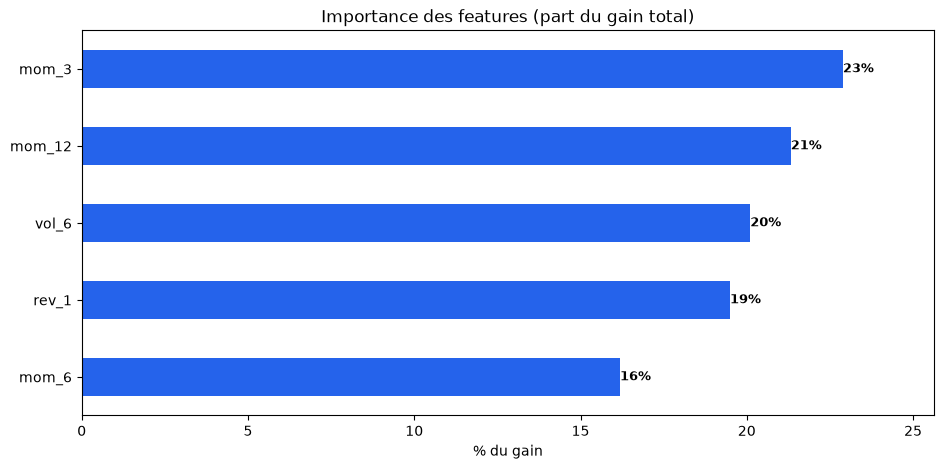

In [3]:
fi = feature_importance(panel)
fi_pct = (fi / fi.sum() * 100).sort_values()
ax = fi_pct.plot.barh(color=ML)
for i, v in enumerate(fi_pct):
    ax.annotate(f'{v:.0f}%', (v, i), va='center', fontsize=9, fontweight='bold')
ax.set(title='Importance des features (part du gain total)', xlabel='% du gain')
ax.margins(x=0.12);

**Lecture.** L'importance est **remarquablement plate** : de `mom_6` (16 %) à `mom_3` (23 %), aucune feature ne domine. Le modèle s'appuie surtout sur les momentums courts et longs (`mom_3`, `mom_12` ≈ 44 % à eux deux), mais répartit le reste sur la volatilité et le retournement. Autrement dit, il **n'a pas découvert de signal nouveau** : il redécoupe le même momentum que la règle simple, en le diluant un peu.

## 3. Courbe de capital

Valeur d'1 $ investi au départ, sur la période commune aux trois approches. Échelle log.

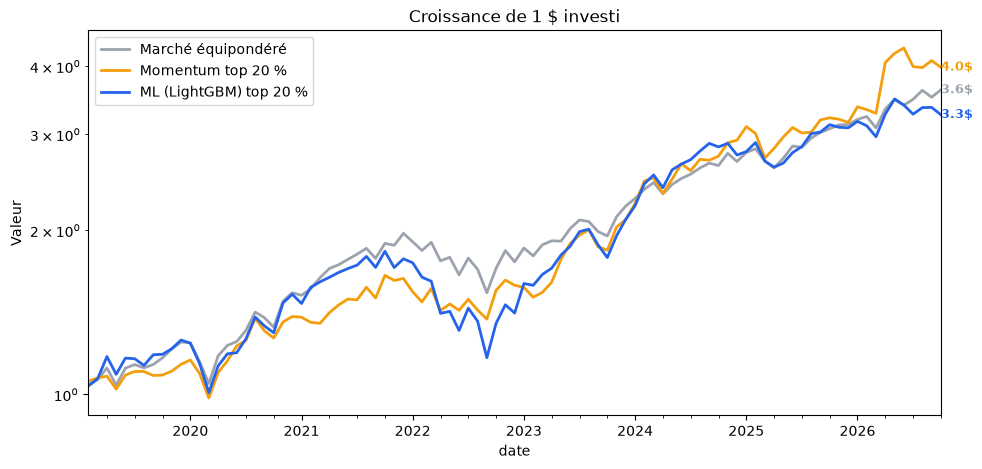

In [4]:
eq = equity_curve(comp)
ax = eq['Marché'].plot(color=BENCH, linewidth=2, label='Marché équipondéré')
eq['Momentum'].plot(ax=ax, color=MOM, linewidth=2, label='Momentum top 20 %')
eq['ML'].plot(ax=ax, color=ML, linewidth=2, label='ML (LightGBM) top 20 %')
for col, color in [('ML', ML), ('Momentum', MOM), ('Marché', BENCH)]:
    ax.annotate(f'{eq[col].iloc[-1]:.1f}$', (eq.index[-1], eq[col].iloc[-1]),
                color=color, fontsize=9, fontweight='bold', va='center')
ax.set(title='Croissance de 1 $ investi', ylabel='Valeur', yscale='log')
ax.legend();

**Lecture.** Au bout du compte, 1 \$ devient **4,0 \$** avec le momentum, **3,6 \$** avec le marché et seulement **3,3 \$** avec le ML. Le modèle appris **arrive dernier**. Surtout, sa courbe est bien plus heurtée : elle décroche violemment en 2022 puis rattrape en 2023. Plus de machinerie, plus d'à-coups, et au final moins de capital.

## 4. Drawdowns comparés

Perte depuis le plus haut atteint, à chaque mois. C'est souvent là que le bât blesse pour un modèle qui change d'avis chaque mois.

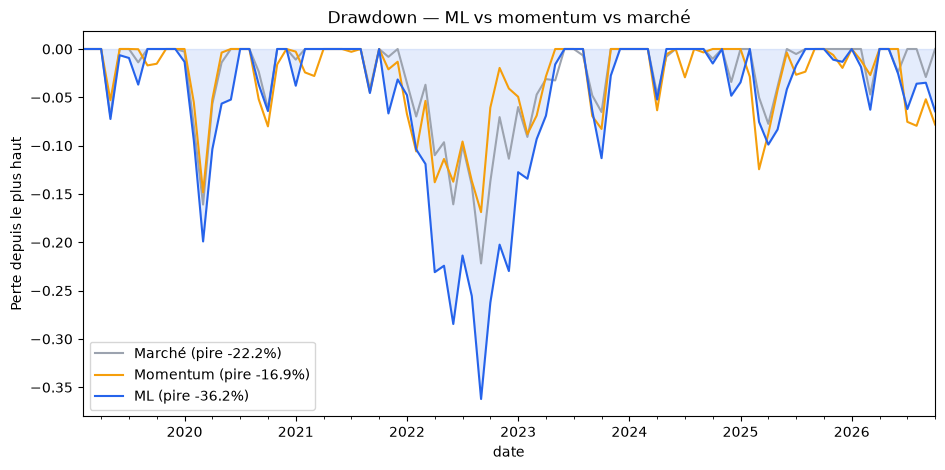

In [5]:
fig, ax = plt.subplots()
for col, color, label in [('Marché', BENCH, 'Marché'), ('Momentum', MOM, 'Momentum'), ('ML', ML, 'ML')]:
    dd = drawdown(comp[col])
    dd.plot(ax=ax, color=color, linewidth=1.5, label=f'{label} (pire {dd.min():.1%})')
ax.fill_between(comp.index, drawdown(comp['ML']), 0, color=ML, alpha=0.12)
ax.set(title='Drawdown — ML vs momentum vs marché', ylabel='Perte depuis le plus haut')
ax.legend();

**Lecture.** C'est le point noir du ML : son pire creux atteint **-36 %**, contre **-22 %** pour le marché et seulement **-17 %** pour le momentum. En réagissant mois après mois, le modèle se fait piéger par les retournements de 2022 et concentre ses paris au mauvais moment. La règle simple, elle, sort des titres qui décrochent plus proprement — sa discipline est ici un **avantage**, pas une limite.

## 5. Tableau de performance

Rendement annualisé, volatilité, Sharpe et pire drawdown, net de coûts, sur la période commune.

In [6]:
comp.apply(performance).T

,rendement_annuel,volatilite_annuelle,sharpe,max_drawdown
ML,0.165,0.201,0.861,-0.362
Momentum,0.195,0.187,1.050,-0.169
Marché,0.181,0.156,1.149,-0.222


**Lecture.** Le verdict est net sur le **Sharpe** : marché **1,15** > momentum **1,05** > ML **0,86**. Le modèle appris gagne moins (**16,5 %** par an contre 19,5 % et 18,1 %), pour une volatilité plus forte (**20,1 %**) et le pire drawdown. Il est **dominé sur tous les tableaux** — rendement, risque et perte maximale. Ajouter de la complexité n'a ici rien apporté.

## 6. Rendement par année civile

Où le modèle gagne-t-il ou perd-il son retard ?

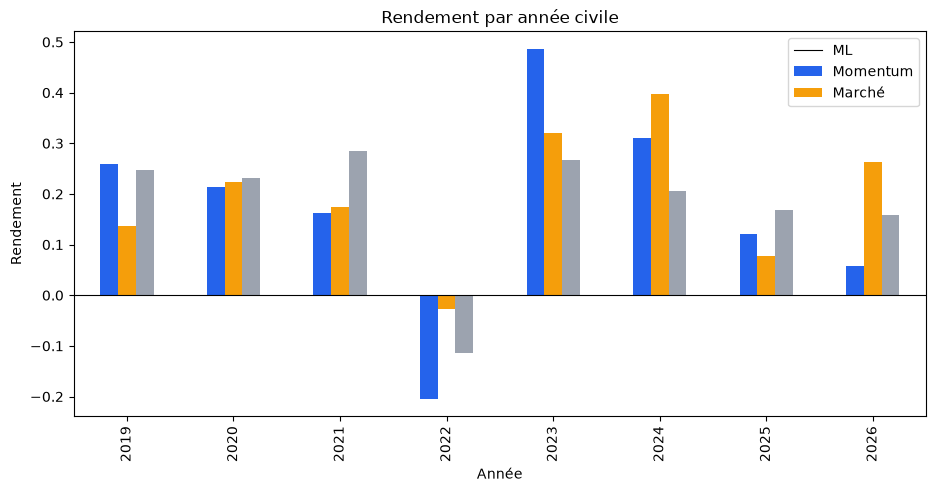

In [7]:
annual = comp.groupby(comp.index.year).apply(lambda r: (1 + r).prod() - 1)
ax = annual.plot.bar(color=[ML, MOM, BENCH])
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Rendement par année civile', ylabel='Rendement', xlabel='Année')
ax.legend(['ML', 'Momentum', 'Marché']);

**Lecture.** Le ML ne bat le marché que **3 années sur 8**. Tout se joue sur deux années extrêmes : **2022** (-20 % contre -3 % pour le momentum et -11 % pour le marché) le plombe durablement, puis **2023** (+49 %) le fait rebondir spectaculairement. Ce profil « tout ou rien » est exactement ce qu'un investisseur veut éviter : la surperformance ponctuelle ne compense pas l'instabilité.

## À retenir

- **La règle simple gagne.** Sur la période commune, le momentum 12-1 domine le modèle ML en rendement **et** en Sharpe **et** en drawdown. Le marché équipondéré reste le meilleur en risque/rendement.
- **Pourquoi ?** Le modèle ne trouve pas de signal nouveau (importances plates, dominées par le momentum lui-même) mais y ajoute du bruit et des à-coups — d'où un drawdown de **-36 %**.
- **La leçon méthodologique** : un modèle plus sophistiqué n'est pas meilleur par défaut ; il faut le mesurer honnêtement, en walk-forward, contre une baseline simple. Ici le résultat négatif est un **bon résultat de recherche**.
- Mêmes limites que les étapes précédentes : **biais du survivant**, 50 actions, features volontairement basiques. Pistes : enrichir les features, optimiser les hyperparamètres en walk-forward, ou tester un classement cross-sectional plutôt qu'une régression du rendement.
- Prochaine étape (étape 6) : **attribution factorielle (Fama-French)** — l'alpha momentum survit-il une fois contrôlé par marché / taille / value ?